# Task 1 — Analysis of the KIBA drug–target dataset

This notebook loads the KIBA benchmark (DeepDTA release), documents its format, cleans it,
and visualises its score distribution, sparsity and ligand / target properties.

**Outputs**
- `data/processed/kiba_*.csv` — cleaned long-format table, ligand / target tables, ligand ID map
- `results/kiba/*.csv|md` — every table shown below
- `figures/kiba/*.png` — every figure shown below

Run from the project root or from `notebooks/`; paths resolve either way.

In [1]:
import collections
import json
from itertools import combinations
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "kiba"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "figures" / "kiba"
RES = ROOT / "results" / "kiba"
for p in (OUT, FIG, RES):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

# Plot style: one blue for data, orange only for flagged / highlighted records, recessive grey axes.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, BOX = "#0b0b0b", "#52514e", "#e5e5e2", "#c9c8c2"
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
SEQ = LinearSegmentedColormap.from_list("kiba_blue", ["#d6e6f8", BLUE, "#0b2f5e"])
STRONG = 12.1  # KIBA strong-binder threshold used in the KIBA literature (Tang et al. 2014; He et al. 2017)


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


def save_table(df, name, index=False):
    df.to_csv(RES / f"{name}.csv", index=index)
    (RES / f"{name}.md").write_text(df.to_markdown(index=index), encoding="utf-8")
    return df


def short(s, n=45):
    return s if len(s) <= n else s[:n] + "…"

## 1. Load the raw files and check they are consistent

Files (DeepDTA, `data/kiba/`):
- `ligands_can.txt`, `ligands_iso.txt` — JSON dicts `CHEMBL ID → SMILES` (canonical / isomeric)
- `proteins.txt` — JSON dict `UniProt ID → amino-acid sequence`
- `kiba_binding_affinity_v2.txt` — 2,111 × 229 tab-separated score matrix, `nan` = not measured.
  This is the *transformed* KIBA score used by DeepDTA, where **higher = stronger binding**, so no
  further transformation is applied.
- `folds/*.txt` — DeepDTA fold indices into the observed entries (used here only as a consistency check)

The matrix is read from the text file rather than the pickled `Y`: unpickling a downloaded file can
execute code, and the text file holds the same matrix (DeepDTA README).

*Loading convention (OrderedDict JSON, row/column order = file order, fold indices into
`np.where(~isnan(Y))`) follows the DeepDTA data README: https://github.com/hkmztrk/DeepDTA/tree/master/data*

In [2]:
OD = collections.OrderedDict
lig_can = json.load(open(RAW / "ligands_can.txt"), object_pairs_hook=OD)
lig_iso = json.load(open(RAW / "ligands_iso.txt"), object_pairs_hook=OD)
proteins = json.load(open(RAW / "proteins.txt"), object_pairs_hook=OD)
Y = np.loadtxt(RAW / "kiba_binding_affinity_v2.txt")

lig_ids, tgt_ids = list(lig_can), list(proteins)
test_fold = json.load(open(RAW / "folds" / "test_fold_setting1.txt"))
train_folds = json.load(open(RAW / "folds" / "train_fold_setting1.txt"))
fold_idx = test_fold + [i for f in train_folds for i in f]

# Sanity checks — the notebook stops here if the files disagree with each other
assert Y.shape == (len(lig_ids), len(tgt_ids)) == (2111, 229)
assert list(lig_iso) == lig_ids, "canonical and isomeric SMILES files list ligands in different order"
assert len(set(fold_idx)) == (~np.isnan(Y)).sum() == 118_254, "fold indices do not cover the observed entries"
print(f"Matrix {Y.shape[0]} ligands x {Y.shape[1]} targets, {(~np.isnan(Y)).sum():,} non-NaN entries — all checks passed")

Matrix 2111 ligands x 229 targets, 118,254 non-NaN entries — all checks passed


### Table 1 — Data format examples

In [3]:
t1a = pd.DataFrame({
    "ligand_id": lig_ids[:3],
    "canonical SMILES": [short(lig_can[k]) for k in lig_ids[:3]],
    "SMILES length": [len(lig_can[k]) for k in lig_ids[:3]],
})
t1b = pd.DataFrame({
    "target_id (UniProt)": tgt_ids[:3],
    "amino-acid sequence": [short(proteins[k]) for k in tgt_ids[:3]],
    "sequence length": [len(proteins[k]) for k in tgt_ids[:3]],
})
t1c = pd.DataFrame(Y[:5, :6], index=lig_ids[:5], columns=tgt_ids[:6]).round(2)
t1c = t1c.map(lambda v: "`nan`" if pd.isna(v) else f"{v:g}")
t1c.index.name = "ligand \\ target"
save_table(t1a, "table1a_ligands_format")
save_table(t1b, "table1b_proteins_format")
save_table(t1c, "table1c_matrix_format", index=True)
display(t1a, t1b, t1c)

,ligand_id,canonical SMILES,SMILES length
0,CHEMBL1087421,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,45
1,CHEMBL1088633,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=CC=C3)Cl)Cl,41
2,CHEMBL1090360,C1COCCN1C2=CC(=CC=C2)NC3=NC=CC(=N3)C4=C(N=C5N…,83


,target_id (UniProt),amino-acid sequence,sequence length
0,O00141,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANN…,431
1,O00311,MEASLGIQMDEPMAFSPQRDRFQAEGSLKKNEQNFKLAGVKKDIE…,574
2,O00329,MPPGVDCPMEFWTKEENQSVVVDFLLPTGVYLNFPVSRNANLSTI…,1044


,O00141,O00311,O00329,O00418,O00444,O14757
ligand \ target,,,,,,
CHEMBL1087421,11.1,`nan`,`nan`,`nan`,`nan`,`nan`
CHEMBL1088633,11.1,`nan`,`nan`,`nan`,`nan`,`nan`
CHEMBL1090360,12.1,12,`nan`,`nan`,`nan`,12.12
CHEMBL1688215,11.1,`nan`,`nan`,`nan`,`nan`,11.1
CHEMBL1765781,12.1,`nan`,`nan`,`nan`,`nan`,12.1


## 2. Data cleaning

### 2.1 Matrix → long format; missing entries are *not measured*, not zero
Each NaN is a ligand–target pair that was never measured. It is dropped from the observation table
but never replaced by 0 — a missing value says nothing about whether the pair binds.

In [4]:
r, c = np.where(~np.isnan(Y))
raw = pd.DataFrame({"ligand_id": np.array(lig_ids)[r], "target_id": np.array(tgt_ids)[c], "score": Y[r, c]})
n_positions = Y.size
print(f"matrix positions: {n_positions:,} | observed: {len(raw):,} | missing: {n_positions - len(raw):,} "
      f"({1 - len(raw) / n_positions:.2%} sparsity)")
t1d = raw.head(4).assign(score=lambda d: d.score.round(3))
save_table(t1d, "table1d_long_format")
t1d

matrix positions: 483,419 | observed: 118,254 | missing: 365,165 (75.54% sparsity)


,ligand_id,target_id,score
0,CHEMBL1087421,O00141,11.1
1,CHEMBL1087421,O14920,11.1
2,CHEMBL1087421,O15111,11.1
3,CHEMBL1087421,P00533,11.1


### 2.2 Non-finite scores and value range
The brief asks us to exclude non-finite scores. KIBA has none (no ±inf); we still check and log it.
All scores are ≥ 0, so there is no impossible negative value either. the brief's "positive Kd" rule does
not apply because KIBA scores are already a transformed composite, not raw Kd.

In [5]:
nonfinite = ~np.isfinite(raw.score)
print("non-finite scores:", int(nonfinite.sum()))
raw = raw[~nonfinite].reset_index(drop=True)
assert (raw.score >= 0).all()
print(f"score range {raw.score.min():.3f} – {raw.score.max():.3f}")

non-finite scores: 0
score range 0.000 – 17.200


### 2.3 Validity of the inputs (SMILES and sequences)

In [6]:
aa = set("ACDEFGHIKLMNPQRSTVWY")
bad_seq = [k for k, s in proteins.items() if set(s) - aa]
salts = [k for k, s in lig_can.items() if "." in s]
smi_len = pd.Series({k: len(s) for k, s in lig_can.items()})
seq_len = pd.Series({k: len(s) for k, s in proteins.items()})
print("sequences with non-standard amino acids:", len(bad_seq))
print("SMILES with '.' (salt / counter-ion, multi-component):", len(salts), "— kept, flagged in ligand table")
print(f"SMILES length {smi_len.min()}–{smi_len.max()} (median {smi_len.median():.0f}); "
      f"sequence length {seq_len.min()}–{seq_len.max()} (median {seq_len.median():.0f})")

sequences with non-standard amino acids: 0
SMILES with '.' (salt / counter-ion, multi-component): 21 — kept, flagged in ligand table
SMILES length 20–590 (median 54); sequence length 215–4128 (median 620)


### 2.4 Duplicate audit at every identity level
Whether two records are "duplicates" depends on the key used to identify ligands and targets
(brief, Tip 2). We test every key the dataset offers.

In [7]:
pair_can_seq = list(zip(raw.ligand_id.map(lig_can), raw.target_id.map(proteins)))
audit = [
    ("Ligand ID (CHEMBL)", lig_ids),
    ("Isomeric SMILES", list(lig_iso.values())),
    ("Canonical SMILES", list(lig_can.values())),
    ("Target ID (UniProt)", tgt_ids),
    ("Protein sequence", list(proteins.values())),
    ("(ligand ID, target ID) pair", list(zip(raw.ligand_id, raw.target_id))),
    ("(canonical SMILES, sequence) pair", pair_can_seq),
]
t_dup = pd.DataFrame([(k, len(v), len(set(v)), len(v) - len(set(v))) for k, v in audit],
                     columns=["identity key", "records", "unique", "redundant records"])
save_table(t_dup, "table_duplicate_audit")
t_dup

,identity key,records,unique,redundant records
0,Ligand ID (CHEMBL),2111,2111,0
1,Isomeric SMILES,2111,2111,0
2,Canonical SMILES,2111,2068,43
3,Target ID (UniProt),229,229,0
4,Protein sequence,229,229,0
5,"(ligand ID, target ID) pair",118254,118254,0
6,"(canonical SMILES, sequence) pair",118254,117657,597


**Finding.** IDs, isomeric SMILES and sequences are all unique. Duplicates appear only when ligands
are identified by **canonical SMILES**: 43 CHEMBL IDs share a canonical SMILES with another ID.
Their isomeric SMILES all differ, so they are **stereoisomers** — canonical SMILES drops the 3-D
stereo information. Any model that reads canonical SMILES cannot tell them apart, so the same input
would appear with different labels. Below we check how much their scores actually disagree.

In [8]:
lig = pd.DataFrame({"ligand_id": lig_ids,
                    "smiles_can": [lig_can[k] for k in lig_ids],
                    "smiles_iso": [lig_iso[k] for k in lig_ids]})
lig["chembl_num"] = lig.ligand_id.str.replace("CHEMBL", "", regex=False).astype(int)
# Representative of each stereoisomer group = lowest CHEMBL number (stable, reproducible choice)
rep = lig.sort_values("chembl_num").groupby("smiles_can").ligand_id.first()
lig["ligand_rep"] = lig.smiles_can.map(rep)
lig["group_size"] = lig.groupby("smiles_can").ligand_id.transform("size")

groups = lig[lig.group_size > 1]
print(f"stereoisomer groups: {groups.smiles_can.nunique()} | ligands in them: {len(groups)} | "
      f"group sizes: {dict(sorted(collections.Counter(groups.drop_duplicates('smiles_can').group_size).items()))}")

raw = raw.merge(lig[["ligand_id", "ligand_rep"]], on="ligand_id")
pairs = []  # every pair of isomers measured on the same target
for (_, tgt), g in raw[raw.ligand_rep.isin(groups.ligand_rep)].groupby(["ligand_rep", "target_id"]):
    for (a, sa), (b, sb) in combinations(zip(g.ligand_id, g.score), 2):
        pairs.append((a, b, tgt, sa, sb))
iso_pairs = pd.DataFrame(pairs, columns=["ligand_a", "ligand_b", "target_id", "score_a", "score_b"])
iso_pairs["abs_diff"] = (iso_pairs.score_a - iso_pairs.score_b).abs()
iso_r = stats.pearsonr(iso_pairs.score_a, iso_pairs.score_b)[0]
t_iso = pd.DataFrame({
    "statistic": ["isomer pairs measured on the same target", "mean absolute difference", "median absolute difference",
                  "identical scores (difference < 1e-6)", "pairs differing by > 1.0", "Pearson r between isomers"],
    "value": [f"{len(iso_pairs):,}", f"{iso_pairs.abs_diff.mean():.3f}", f"{iso_pairs.abs_diff.median():.3f}",
              f"{(iso_pairs.abs_diff < 1e-6).mean():.1%}", f"{(iso_pairs.abs_diff > 1).sum()}", f"{iso_r:.3f}"],
})
save_table(t_iso, "table_stereoisomer_agreement")
t_iso

stereoisomer groups: 32 | ligands in them: 75 | group sizes: {2: 29, 3: 1, 6: 1, 8: 1}


,statistic,value
0,isomer pairs measured on the same target,952
1,mean absolute difference,0.441
2,median absolute difference,0.301
3,identical scores (difference < 1e-6),24.1%
4,pairs differing by > 1.0,86
5,Pearson r between isomers,0.857


### 2.5 Merge stereoisomers and average repeated pairs
Isomers agree closely on most targets (high r, small median difference) but not perfectly. We merge
each stereoisomer group into its representative ID and **average** the repeated pairs — the mean keeps
every measurement's information (the median of two values *is* the mean anyway, and 29 of 32 groups
have only two members). `score_std` and `n_merged` are kept so the disagreement stays visible, and
`source_ids` lists the original CHEMBL IDs so nothing is lost. `ligand_map.csv` maps every original
ID to its representative.

In [9]:
clean = (raw.groupby(["ligand_rep", "target_id"], as_index=False)
         .agg(score=("score", "mean"), score_std=("score", "std"), n_merged=("score", "size"),
              source_ids=("ligand_id", lambda s: ";".join(sorted(s))))
         .rename(columns={"ligand_rep": "ligand_id"}))
clean["score_std"] = clean.score_std.fillna(0.0)
assert clean.score.notna().all() and not clean.duplicated(["ligand_id", "target_id"]).any()
print(f"rows {len(raw):,} -> {len(clean):,} ({len(raw) - len(clean)} redundant rows merged into "
      f"{(clean.n_merged > 1).sum()} averaged pairs)")

rows 118,254 -> 117,657 (597 redundant rows merged into 473 averaged pairs)


### 2.6 Abnormal values — flagged, never removed
Outlier rule: Tukey's *far-out* fences, Q1 − 3·IQR and Q3 + 3·IQR (Tukey, 1977), computed on the
cleaned scores. Four flags are added; **no row is removed**.

In [10]:
q1, q3 = clean.score.quantile([0.25, 0.75])
iqr = q3 - q1
low_fence, high_fence = q1 - 3 * iqr, q3 + 3 * iqr
clean["flag_far_low"] = clean.score < low_fence
clean["flag_zero"] = clean.score == 0
clean["flag_spike"] = np.isclose(clean.score, 11.1, atol=1e-4) | np.isclose(clean.score, 11.2, atol=1e-4)
clean["flag_far_high"] = clean.score > high_fence
low_share = clean.groupby("ligand_id").flag_far_low.mean()
low_ligands = low_share[low_share > 0.5].index.tolist()
clean["flag_low_ligand"] = clean.ligand_id.isin(low_ligands)
print(f"fences: low {low_fence:.2f}, high {high_fence:.2f} | ligands whose scores are mostly far-low: {low_ligands}")

flag_info = [
    ("flag_zero", "score == 0", "The only zero score in KIBA. Valid on the supplied scale, so kept (brief: keep valid zero scores)."),
    ("flag_far_low", f"score < Q1 − 3·IQR ({low_fence:.2f})", "Extremely weak scores, far below the bulk of the data. Most belong to one ligand."),
    ("flag_low_ligand", "> 50 % of a ligand's scores are far-low", "A ligand-level anomaly: CHEMBL373751's 11 scores average 3.3 vs a dataset mean of 11.7; likely an artefact of the score transformation of its source data."),
    ("flag_spike", "score exactly 11.1 or 11.2", "Heaped values (KIBA's most frequent scores), consistent with rounded / thresholded source measurements — a screening-floor effect."),
    ("flag_far_high", f"score > Q3 + 3·IQR ({high_fence:.2f})", "Very strong binders. These are genuine and the most interesting records; kept."),
]
t_flags = pd.DataFrame([(f, rule, int(clean[f].sum()), f"{clean[f].mean():.2%}", "kept", note)
                        for f, rule, note in flag_info],
                       columns=["flag", "rule", "rows", "% of rows", "action", "interpretation"])
save_table(t_flags, "table_abnormal_flags")
t_flags

fences: low 9.03, high 14.10 | ligands whose scores are mostly far-low: ['CHEMBL373751']


,flag,rule,rows,% of rows,action,interpretation
0,flag_zero,score == 0,1,0.00%,kept,"The only zero score in KIBA. Valid on the supplied scale, so kept ..."
1,flag_far_low,score < Q1 − 3·IQR (9.03),20,0.02%,kept,"Extremely weak scores, far below the bulk of the data. Most belong..."
2,flag_low_ligand,> 50 % of a ligand's scores are far-low,11,0.01%,kept,A ligand-level anomaly: CHEMBL373751's 11 scores average 3.3 vs a ...
3,flag_spike,score exactly 11.1 or 11.2,26922,22.88%,kept,"Heaped values (KIBA's most frequent scores), consistent with round..."
4,flag_far_high,score > Q3 + 3·IQR (14.10),2934,2.49%,kept,Very strong binders. These are genuine and the most interesting re...


### 2.7 Sensitivity check — how much do the flagged records matter?
Keeping abnormal records only makes sense if we know their effect. The table recomputes the summary
statistics with each flagged group left out.

In [11]:
def summary(s):
    return {"pairs": f"{len(s):,}", "mean": round(s.mean(), 3), "median": round(s.median(), 3),
            "std": round(s.std(), 3), "skewness": round(stats.skew(s), 3), "min": round(s.min(), 2),
            "max": round(s.max(), 2), f"% ≥ {STRONG}": f"{(s >= STRONG).mean():.1%}"}

t_sens = pd.DataFrame({
    "all cleaned pairs": summary(clean.score),
    "without far-low": summary(clean.score[~clean.flag_far_low]),
    "without low ligand": summary(clean.score[~clean.flag_low_ligand]),
    "without 11.1/11.2 spikes": summary(clean.score[~clean.flag_spike]),
    "without far-high": summary(clean.score[~clean.flag_far_high]),
}).T.reset_index(names="subset")
save_table(t_sens, "table_sensitivity")
t_sens

,subset,pairs,mean,median,std,skewness,min,max,% ≥ 12.1
0,all cleaned pairs,"117,657",11.721,11.527,0.834,1.177,0.0,17.2,21.0%
1,without far-low,"117,637",11.723,11.532,0.829,1.338,9.1,17.2,21.0%
2,without low ligand,"117,646",11.722,11.531,0.83,1.328,7.1,17.2,21.0%
3,without 11.1/11.2 spikes,"90,735",11.889,11.8,0.883,0.792,0.0,17.2,27.2%
4,without far-high,"114,723",11.649,11.5,0.706,0.529,0.0,14.09,19.0%


### 2.8 Cleaning log and count table (original vs cleaned)

In [12]:
n_lig_clean, n_tgt_clean = clean.ligand_id.nunique(), clean.target_id.nunique()
t_log = pd.DataFrame([
    ("1", "Matrix → long format", f"{n_positions:,} positions", f"{len(raw):,} pairs", f"{n_positions - len(raw):,} NaN dropped", "NaN = not measured (never set to 0)"),
    ("2", "Non-finite scores", f"{len(raw):,}", f"{len(raw):,}", "0", "no ±inf present"),
    ("3", "Range / input validity", f"{len(raw):,}", f"{len(raw):,}", "0", "scores ≥ 0; sequences standard; 21 salt SMILES flagged"),
    ("4", "Merge stereoisomers (canonical SMILES)", f"{len(raw):,}", f"{len(clean):,}", f"{len(raw) - len(clean)} merged", f"{(clean.n_merged > 1).sum()} pairs averaged"),
    ("5", "Abnormal-value flags", f"{len(clean):,}", f"{len(clean):,}", "0 removed", f"{int(clean.filter(like='flag_').any(axis=1).sum()):,} rows carry ≥ 1 flag"),
], columns=["step", "operation", "rows in", "rows out", "change", "note"])
save_table(t_log, "table_cleaning_log")

t_counts = pd.DataFrame({
    "original": [len(lig_ids), len(tgt_ids), f"{len(raw):,}", f"{Y.size:,}", f"{1 - len(raw) / Y.size:.2%}",
                 round(len(raw) / len(lig_ids), 1), round(len(raw) / len(tgt_ids), 1)],
    "cleaned (deduplicated)": [n_lig_clean, n_tgt_clean, f"{len(clean):,}", f"{n_lig_clean * n_tgt_clean:,}",
                               f"{1 - len(clean) / (n_lig_clean * n_tgt_clean):.2%}",
                               round(len(clean) / n_lig_clean, 1), round(len(clean) / n_tgt_clean, 1)],
}, index=["ligands", "targets", "observed pairs", "matrix positions", "sparsity (missing / all positions)",
          "mean observations per ligand", "mean observations per target"]).reset_index(names="")
save_table(t_counts, "table_counts")
display(t_log, t_counts)

,step,operation,rows in,rows out,change,note
0,1,Matrix → long format,"483,419 positions","118,254 pairs","365,165 NaN dropped",NaN = not measured (never set to 0)
1,2,Non-finite scores,"118,254","118,254",0,no ±inf present
2,3,Range / input validity,"118,254","118,254",0,scores ≥ 0; sequences standard; 21 salt SMILES flagged
3,4,Merge stereoisomers (canonical SMILES),"118,254","117,657",597 merged,473 pairs averaged
4,5,Abnormal-value flags,"117,657","117,657",0 removed,"29,877 rows carry ≥ 1 flag"


,,original,cleaned (deduplicated)
0,ligands,2111,2068
1,targets,229,229
2,observed pairs,"118,254","117,657"
3,matrix positions,"483,419","473,572"
4,sparsity (missing / all positions),75.54%,75.16%
5,mean observations per ligand,56.0,56.9
6,mean observations per target,516.4,513.8


### 2.9 Save the cleaned dataset

In [13]:
ligands_out = (lig[lig.ligand_id == lig.ligand_rep]
               .merge(lig.groupby("ligand_rep").ligand_id.agg(lambda s: ";".join(sorted(s))).rename("member_ids"),
                      left_on="ligand_id", right_index=True)
               .assign(n_members=lambda d: d.member_ids.str.count(";") + 1,
                       is_salt=lambda d: d.smiles_can.str.contains(".", regex=False),
                       is_low_ligand=lambda d: d.ligand_id.isin(low_ligands))
               [["ligand_id", "smiles_can", "smiles_iso", "member_ids", "n_members", "is_salt", "is_low_ligand"]]
               .merge(clean.groupby("ligand_id").size().rename("n_targets"), on="ligand_id"))
targets_out = pd.DataFrame({"target_id": tgt_ids, "sequence": [proteins[k] for k in tgt_ids],
                            "length": [len(proteins[k]) for k in tgt_ids]}
                           ).merge(clean.groupby("target_id").size().rename("n_ligands"), on="target_id")

clean.to_csv(OUT / "kiba_pairs_clean.csv", index=False)
ligands_out.to_csv(OUT / "kiba_ligands.csv", index=False)
targets_out.to_csv(OUT / "kiba_targets.csv", index=False)
lig[["ligand_id", "ligand_rep"]].to_csv(OUT / "kiba_ligand_map.csv", index=False)
assert len(ligands_out) == n_lig_clean and len(targets_out) == n_tgt_clean
print("saved:", *sorted(p.name for p in OUT.glob("kiba_*.csv")))

saved: kiba_ligand_map.csv kiba_ligands.csv kiba_pairs_clean.csv kiba_targets.csv


## 3. Visualisation
The cleaned matrix (2,068 × 229) is used for every figure.

In [14]:
C = clean.pivot(index="ligand_id", columns="target_id", values="score")
obs = C.notna()
lig_n, tgt_n = obs.sum(axis=1), obs.sum(axis=0)
s = clean.score

### Figure 1 — Ligand–target heatmap
Rows and columns are sorted by how many measurements they have, so the dense block sits top-left
and the sparse tail bottom-right. **White = not measured.** The colour scale is clipped to the
1st–99th percentiles so the bulk of the scores is readable (arrows on the colour bar mark clipping).

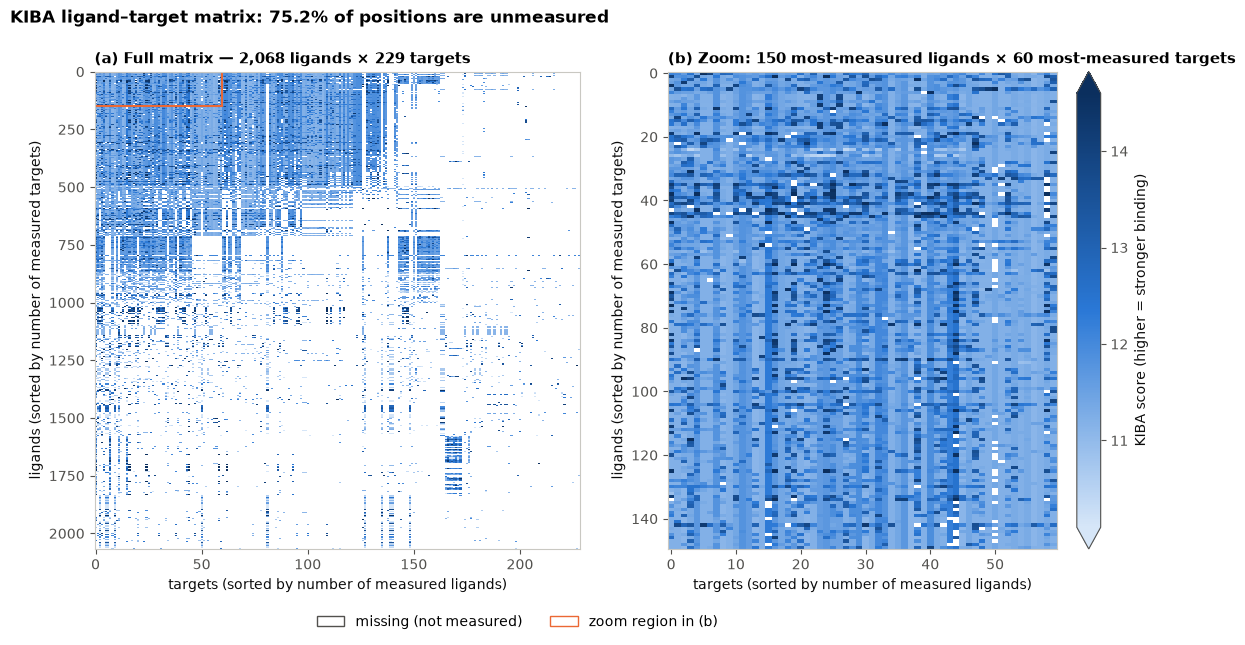

In [15]:
row_order = lig_n.sort_values(ascending=False).index
col_order = tgt_n.sort_values(ascending=False).index
M = C.loc[row_order, col_order].to_numpy()
vmin, vmax = np.percentile(s, [1, 99])
cmap = SEQ.copy()
cmap.set_bad("white")

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
zr, zc = 150, 60
for ax, data, title in [(axes[0], M, f"(a) Full matrix — {len(row_order):,} ligands × {len(col_order)} targets"),
                        (axes[1], M[:zr, :zc], f"(b) Zoom: {zr} most-measured ligands × {zc} most-measured targets")]:
    im = ax.imshow(np.ma.masked_invalid(data), aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title, loc="left")
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(BOX)
    ax.set_xlabel("targets (sorted by number of measured ligands)")
    ax.set_ylabel("ligands (sorted by number of measured targets)")
axes[0].add_patch(plt.Rectangle((-0.5, -0.5), zc, zr, fill=False, ec=ORANGE, lw=1.5))
cb = fig.colorbar(im, ax=axes, extend="both", fraction=0.025, pad=0.02)
cb.set_label("KIBA score (higher = stronger binding)")
fig.legend(handles=[Patch(facecolor="white", edgecolor=INK2, label="missing (not measured)"),
                    Patch(facecolor="none", edgecolor=ORANGE, label="zoom region in (b)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.45, -0.04))
fig.suptitle(f"KIBA ligand–target matrix: {1 - obs.values.mean():.1%} of positions are unmeasured", x=0.06, ha="left", fontsize=12, fontweight="bold")
savefig(fig, "fig1_heatmap")

### Figure 2 — Score distribution (KDE)
Panel (a) shows the KDE of observed scores over the bulk of the data; a narrow-bandwidth KDE is
drawn as well because the default (Scott) bandwidth smooths over the heaped values at 11.1 / 11.2.
Panel (b) uses a log-scaled count axis to show the full range, including the far-low tail that a
density plot hides.

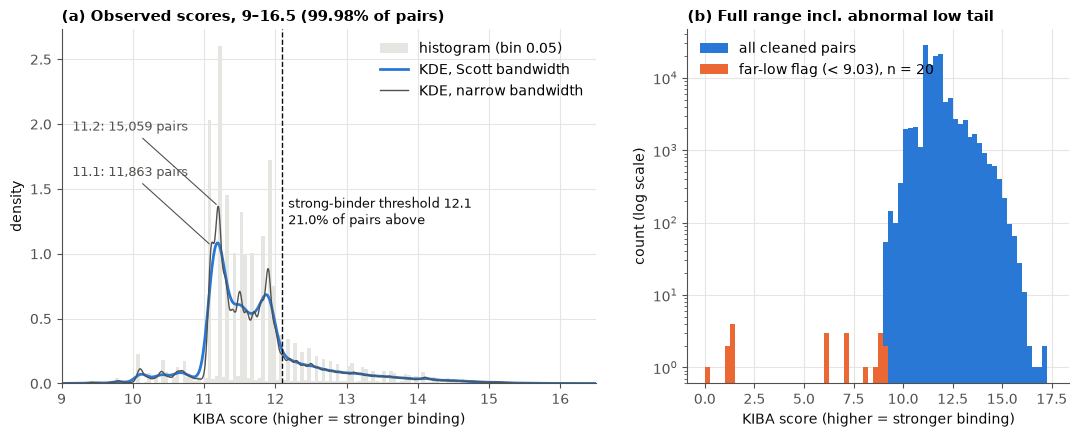

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
xs = np.linspace(9, 16.5, 1200)
ax.hist(s[(s >= 9) & (s <= 16.5)], bins=np.arange(9, 16.55, 0.05), density=True, color=GRID, label="histogram (bin 0.05)")
ax.plot(xs, stats.gaussian_kde(s)(xs), color=BLUE, lw=2, label="KDE, Scott bandwidth")
ax.plot(xs, stats.gaussian_kde(s, bw_method=0.05)(xs), color=INK2, lw=1, label="KDE, narrow bandwidth")
ax.axvline(STRONG, color=INK, ls="--", lw=1)
ax.text(STRONG + 0.08, 1.45, f"strong-binder threshold {STRONG}\n{(s >= STRONG).mean():.1%} of pairs above",
        color=INK, fontsize=9, va="top")
for v in (11.1, 11.2):
    ax.annotate(f"{v}: {np.isclose(s, v, atol=1e-4).sum():,} pairs", xy=(v, stats.gaussian_kde(s, bw_method=0.05)(v)[0]),
                xytext=(9.15, (1.95 if v == 11.2 else 1.6)), fontsize=9, color=INK2,
                arrowprops={"arrowstyle": "-", "color": INK2, "lw": 0.8})
ax.set_xlim(9, 16.5)
ax.set_xlabel("KIBA score (higher = stronger binding)")
ax.set_ylabel("density")
ax.set_title(f"(a) Observed scores, 9–16.5 ({((s >= 9) & (s <= 16.5)).mean():.2%} of pairs)", loc="left")
ax.legend(loc="upper right")

ax = axes[1]
bins = np.arange(0, 17.6, 0.25)
ax.hist(s, bins=bins, color=BLUE, label="all cleaned pairs")
ax.hist(s[clean.flag_far_low], bins=bins, color=ORANGE, label=f"far-low flag (< {low_fence:.2f}), n = {clean.flag_far_low.sum()}")
ax.set_yscale("log")
ax.set_xlabel("KIBA score (higher = stronger binding)")
ax.set_ylabel("count (log scale)")
ax.set_title("(b) Full range incl. abnormal low tail", loc="left")
ax.legend(loc="upper left")
savefig(fig, "fig2_score_distribution")

### Figure 3 — Observation coverage per ligand and per target

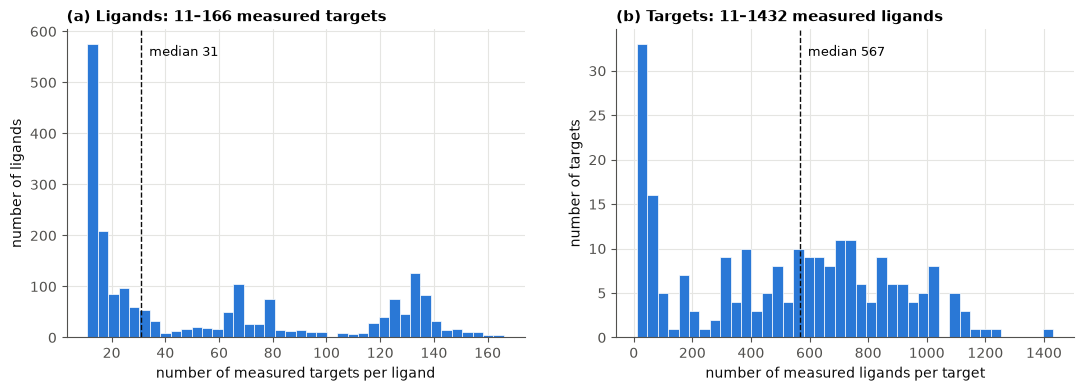

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, counts, what, other in [(axes[0], lig_n, "ligand", "targets"), (axes[1], tgt_n, "target", "ligands")]:
    ax.hist(counts, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axvline(counts.median(), color=INK, ls="--", lw=1)
    ax.text(counts.median(), ax.get_ylim()[1] * 0.95, f"  median {counts.median():.0f}", va="top", fontsize=9)
    ax.set_xlabel(f"number of measured {other} per {what}")
    ax.set_ylabel(f"number of {what}s")
    ax.set_title(f"({'a' if what == 'ligand' else 'b'}) {what.capitalize()}s: {counts.min()}–{counts.max()} measured {other}", loc="left")
savefig(fig, "fig3_coverage")

### Figure 4 — Missing ≠ non-binding: is missingness related to the score?
If pairs were missing at random, a ligand's average score would not depend on how many targets it
was tested on. Spearman correlation tests this.

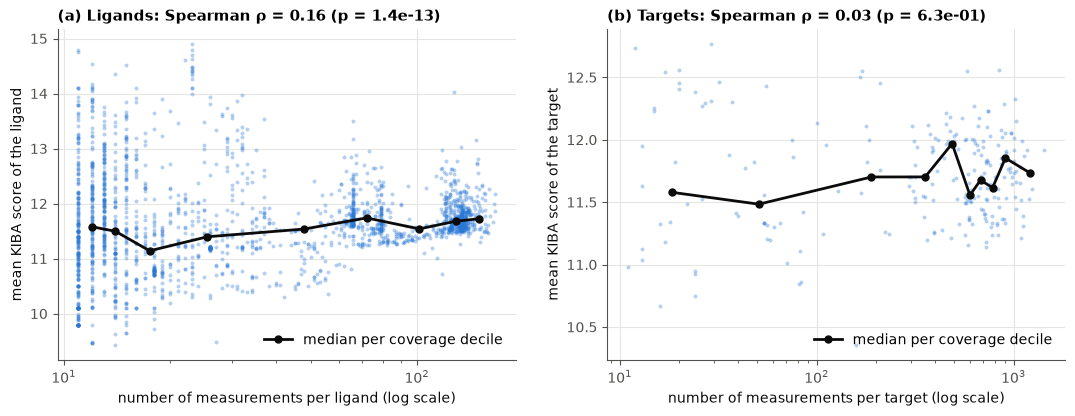

In [18]:
lig_mean, tgt_mean = C.mean(axis=1), C.mean(axis=0)
rho_l, p_l = stats.spearmanr(lig_n, lig_mean)
rho_t, p_t = stats.spearmanr(tgt_n, tgt_mean)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, n, m, rho, p, lab, tag in [(axes[0], lig_n, lig_mean, rho_l, p_l, "ligand", "a"), (axes[1], tgt_n, tgt_mean, rho_t, p_t, "target", "b")]:
    keep = m > 8  # the single low ligand is shown in Figure 5 instead
    ax.scatter(n[keep], m[keep], s=8, color=BLUE, alpha=0.35, linewidths=0)
    q = pd.qcut(n[keep], 10, duplicates="drop")
    med = m[keep].groupby(q, observed=True).median()
    ax.plot([iv.mid for iv in med.index], med.values, color=INK, lw=2, marker="o", ms=5, label="median per coverage decile")
    ax.set_xscale("log")
    ax.set_xlabel(f"number of measurements per {lab} (log scale)")
    ax.set_ylabel(f"mean KIBA score of the {lab}")
    ax.set_title(f"({tag}) {lab.capitalize()}s: Spearman ρ = {rho:.2f} (p = {p:.1e})", loc="left")
    ax.legend(loc="lower right")
savefig(fig, "fig4_missingness_vs_score")

### Figure 5 — The abnormal ligand CHEMBL373751 against every other ligand on the same targets

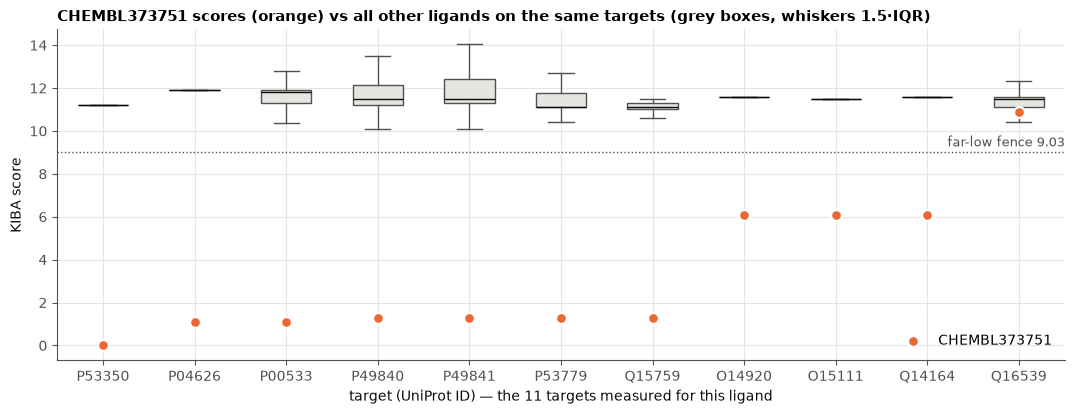

In [19]:
odd = low_ligands[0]
odd_t = C.loc[odd].dropna().sort_values().index
others = [C.loc[C.index != odd, t].dropna().to_numpy() for t in odd_t]
fig, ax = plt.subplots(figsize=(13, 4.3))
ax.boxplot(others, positions=range(len(odd_t)), widths=0.55, showfliers=False, patch_artist=True,
           boxprops={"facecolor": GRID, "edgecolor": INK2}, medianprops={"color": INK}, whiskerprops={"color": INK2}, capprops={"color": INK2})
ax.scatter(range(len(odd_t)), C.loc[odd, odd_t], color=ORANGE, s=60, zorder=3, edgecolor="white", linewidth=1.5, label=odd)
ax.axhline(low_fence, color=INK2, ls=":", lw=1)
ax.text(len(odd_t) - 0.5, low_fence + 0.25, f"far-low fence {low_fence:.2f}", ha="right", fontsize=9, color=INK2)
ax.set_xticks(range(len(odd_t)), odd_t, rotation=0)
ax.set_xlabel("target (UniProt ID) — the 11 targets measured for this ligand")
ax.set_ylabel("KIBA score")
ax.set_title(f"{odd} scores (orange) vs all other ligands on the same targets (grey boxes, whiskers 1.5·IQR)", loc="left")
ax.legend(loc="lower right")
savefig(fig, "fig5_abnormal_ligand")

### Figure 6 — Stereoisomer consistency (justifies averaging)

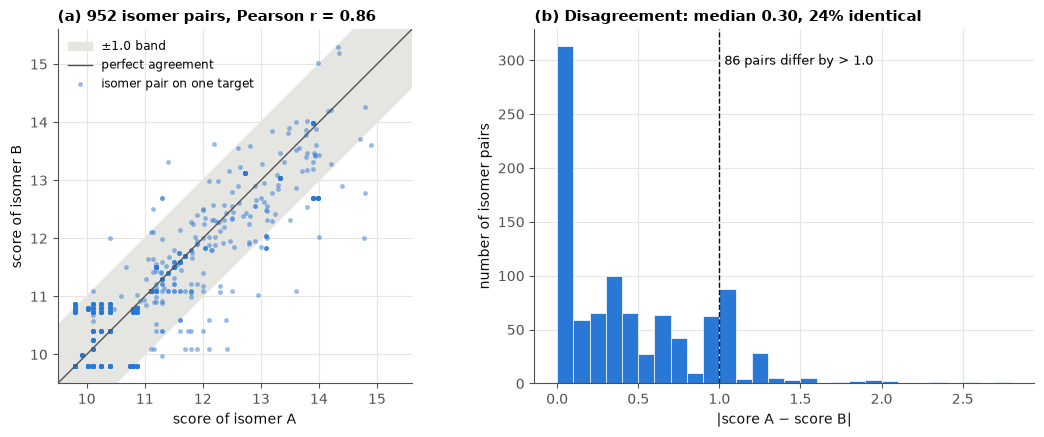

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
lo, hi = iso_pairs[["score_a", "score_b"]].min().min() - 0.3, iso_pairs[["score_a", "score_b"]].max().max() + 0.3
ax.fill_between([lo, hi], [lo - 1, hi - 1], [lo + 1, hi + 1], color=GRID, label="±1.0 band")
ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, label="perfect agreement")
ax.scatter(iso_pairs.score_a, iso_pairs.score_b, s=12, color=BLUE, alpha=0.5, linewidths=0, label="isomer pair on one target")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("score of isomer A"); ax.set_ylabel("score of isomer B")
ax.set_title(f"(a) {len(iso_pairs):,} isomer pairs, Pearson r = {iso_r:.2f}", loc="left")
ax.legend(loc="upper left", fontsize=8.5)
ax = axes[1]
ax.hist(iso_pairs.abs_diff, bins=np.arange(0, iso_pairs.abs_diff.max() + 0.1, 0.1), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(1, color=INK, ls="--", lw=1)
ax.text(1.03, ax.get_ylim()[1] * 0.9, f"{(iso_pairs.abs_diff > 1).sum()} pairs differ by > 1.0", fontsize=9)
ax.set_xlabel("|score A − score B|"); ax.set_ylabel("number of isomer pairs")
ax.set_title(f"(b) Disagreement: median {iso_pairs.abs_diff.median():.2f}, {(iso_pairs.abs_diff < 1e-6).mean():.0%} identical", loc="left")
savefig(fig, "fig6_stereoisomers")

### Figure 7 — Target properties: per-target score spread and protein-family structure
(a) every target's median score with its interquartile range, ranked.
(b) the supplied Smith–Waterman target–target similarity matrix, reordered by average-linkage
hierarchical clustering (distance = 1 − similarity) so related proteins sit together.

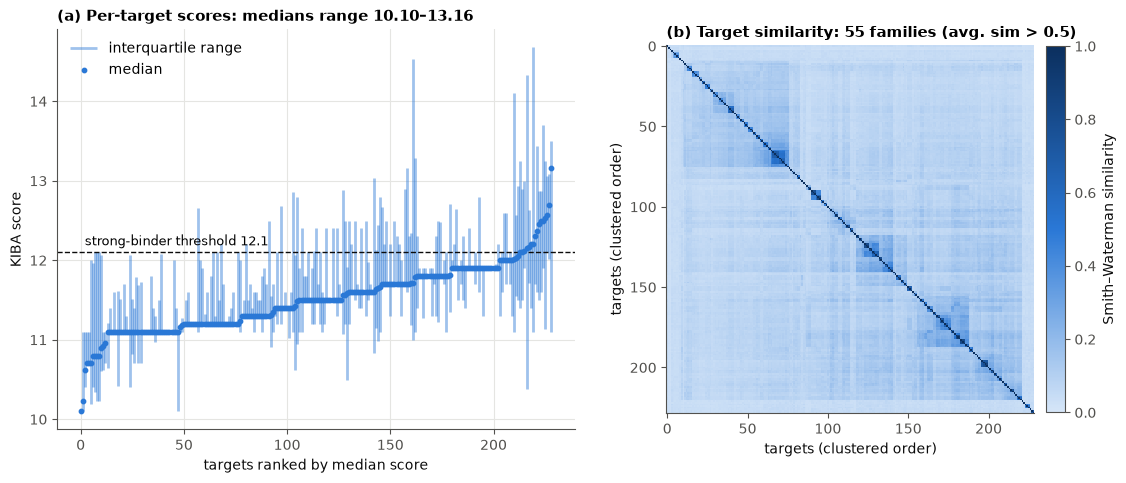

family sizes (> 1): [8, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [21]:
tsim = pd.DataFrame(np.loadtxt(RAW / "kiba_target_sim.txt"), index=tgt_ids, columns=tgt_ids)
assert np.allclose(tsim, tsim.T) and np.allclose(np.diag(tsim), 1)
Z = linkage(squareform(1 - tsim.to_numpy(), checks=False), method="average")
order = leaves_list(Z)
fam = fcluster(Z, t=0.5, criterion="distance")  # targets joined at similarity > 0.5
fam_sizes = pd.Series(fam).value_counts()

tstats = pd.DataFrame({"median": C.median(axis=0), "q1": C.quantile(0.25), "q3": C.quantile(0.75), "n": tgt_n}).sort_values("median")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
x = np.arange(len(tstats))
ax.vlines(x, tstats.q1, tstats.q3, color=BLUE, alpha=0.45, lw=2, label="interquartile range")
ax.scatter(x, tstats["median"], s=10, color=BLUE, zorder=3, label="median")
ax.axhline(STRONG, color=INK, ls="--", lw=1)
ax.text(2, STRONG + 0.05, f"strong-binder threshold {STRONG}", fontsize=9, va="bottom")
ax.set_xlabel("targets ranked by median score"); ax.set_ylabel("KIBA score")
ax.set_title(f"(a) Per-target scores: medians range {tstats['median'].min():.2f}–{tstats['median'].max():.2f}", loc="left")
ax.legend(loc="upper left")
ax = axes[1]
im = ax.imshow(tsim.to_numpy()[np.ix_(order, order)], cmap=SEQ, vmin=0, vmax=1, interpolation="nearest")
ax.grid(False)
ax.set_xlabel("targets (clustered order)"); ax.set_ylabel("targets (clustered order)")
ax.set_title(f"(b) Target similarity: {(fam_sizes > 1).sum()} families (avg. sim > 0.5)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03).set_label("Smith–Waterman similarity")
savefig(fig, "fig7_target_properties")
print("family sizes (> 1):", sorted(fam_sizes[fam_sizes > 1].tolist(), reverse=True))

### Figure 8 — Do similar ligands / similar targets have similar affinity profiles?
For every pair of ligands (and every pair of targets) we compute the Pearson correlation of their
scores on the entities **both** were measured on (at least 10 in common), and relate it to the
supplied structural similarity. This "guilt-by-association" idea — similar molecules bind alike —
is the premise of similarity-based DTA methods (He et al. 2017, SimBoost; Kim et al. 2025, MixingDTA).

*The overlap correlation is computed for all pairs at once with masked matrix products
(sums of x, y, x², y², xy restricted to co-observed entries) — our own implementation.*

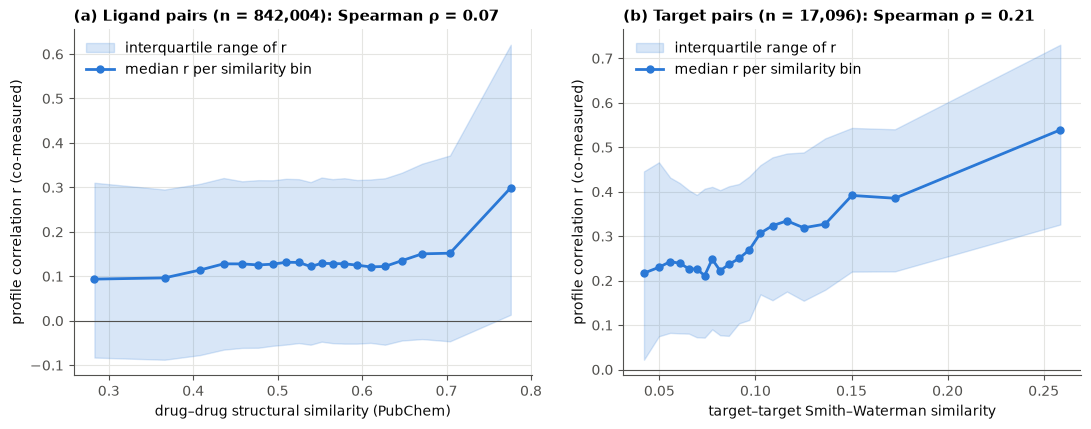

,entity,pairs (≥10 shared),"Spearman ρ(sim, r)","median r, bottom-50% similarity","median r, top-5% similarity"
0,ligand,"842,004",0.072,0.120,0.297
1,target,"17,096",0.213,0.229,0.539


In [22]:
def overlap_corr(X, min_overlap=10):
    """Pearson r between rows of X (NaN = missing) using only co-observed columns."""
    Mk = (~np.isnan(X)).astype(float)
    X0 = np.nan_to_num(X)
    n = Mk @ Mk.T
    sx = X0 @ Mk.T                     # sum of x_i over columns observed for both i and j
    sxx = (X0 ** 2) @ Mk.T
    sxy = X0 @ X0.T
    with np.errstate(invalid="ignore", divide="ignore"):
        cov = sxy - sx * sx.T / n
        r = cov / np.sqrt((sxx - sx ** 2 / n) * (sxx.T - sx.T ** 2 / n))
    iu = np.triu_indices_from(n, k=1)
    keep = (n[iu] >= min_overlap) & np.isfinite(r[iu])
    return iu[0][keep], iu[1][keep], r[iu][keep], n[iu][keep]

dsim_full = np.loadtxt(RAW / "kiba_drug_sim.txt")
pos = {k: i for i, k in enumerate(lig_ids)}
lig_idx = [pos[k] for k in C.index]  # representative ligands' rows in the original similarity matrix

gba = {}
li, lj, lr, ln = overlap_corr(C.to_numpy())
gba["ligand"] = pd.DataFrame({"sim": dsim_full[np.array(lig_idx)[li], np.array(lig_idx)[lj]], "r": lr, "n": ln})
ti, tj, tr, tn = overlap_corr(C.to_numpy().T)
gba["target"] = pd.DataFrame({"sim": tsim.to_numpy()[ti, tj], "r": tr, "n": tn})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rows = []
for ax, (what, d), simlab, tag in zip(axes, gba.items(), ["drug–drug structural similarity (PubChem)", "target–target Smith–Waterman similarity"], "ab"):
    b = pd.qcut(d.sim, 20, duplicates="drop")  # equal-count similarity bins
    g = d.groupby(b, observed=True).r
    mids = d.groupby(b, observed=True).sim.median().to_numpy()  # plot each bin at its median similarity
    ax.fill_between(mids, g.quantile(0.25), g.quantile(0.75), color=BLUE, alpha=0.18, label="interquartile range of r")
    ax.plot(mids, g.median(), color=BLUE, lw=2, marker="o", ms=5, label="median r per similarity bin")
    rho = stats.spearmanr(d.sim, d.r)[0]
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xlabel(simlab); ax.set_ylabel("profile correlation r (co-measured)")
    ax.set_title(f"({tag}) {what.capitalize()} pairs (n = {len(d):,}): Spearman ρ = {rho:.2f}", loc="left")
    ax.legend(loc="upper left")
    top = d[d.sim >= d.sim.quantile(0.95)].r.median()
    low = d[d.sim <= d.sim.quantile(0.50)].r.median()
    rows.append((what, f"{len(d):,}", round(rho, 3), round(low, 3), round(top, 3)))
savefig(fig, "fig8_similarity_vs_profile")
t_gba = save_table(pd.DataFrame(rows, columns=["entity", "pairs (≥10 shared)", "Spearman ρ(sim, r)",
                                               "median r, bottom-50% similarity", "median r, top-5% similarity"]),
                   "table_similarity_vs_profile")
t_gba

## 4. Where does the variation in scores come from?
A two-way additive decomposition (score ≈ overall mean + ligand effect + target effect), fitted by
alternating least squares on the observed pairs. This is a classical ANOVA-style summary, not a
predictive model: it shows whether *which ligand* or *which target* explains more of the variation.

In [23]:
li_codes, li_names = pd.factorize(clean.ligand_id)
ti_codes, ti_names = pd.factorize(clean.target_id)
y = clean.score.to_numpy()
sst = ((y - y.mean()) ** 2).sum()

def r2(pred):
    return 1 - ((y - pred) ** 2).sum() / sst

lig_only = pd.Series(y).groupby(li_codes).transform("mean").to_numpy()
tgt_only = pd.Series(y).groupby(ti_codes).transform("mean").to_numpy()
mu, bl, bt = y.mean(), np.zeros(len(li_names)), np.zeros(len(ti_names))
for _ in range(50):
    bl = pd.Series(y - mu - bt[ti_codes]).groupby(li_codes).mean().to_numpy()
    bt = pd.Series(y - mu - bl[li_codes]).groupby(ti_codes).mean().to_numpy()
additive = mu + bl[li_codes] + bt[ti_codes]
t_var = save_table(pd.DataFrame({
    "explained by": ["ligand identity only", "target identity only", "ligand + target (additive)", "residual (ligand × target interaction + noise)"],
    "R² (share of score variance)": [f"{r2(lig_only):.1%}", f"{r2(tgt_only):.1%}", f"{r2(additive):.1%}", f"{1 - r2(additive):.1%}"],
}), "table_variance_decomposition")
t_var

,explained by,R² (share of score variance)
0,ligand identity only,41.7%
1,target identity only,14.1%
2,ligand + target (additive),51.9%
3,residual (ligand × target interaction + noise),48.1%


## 5. Summary of findings
See `README.md` for the full written report, which embeds every figure and table produced above.